<a href="https://colab.research.google.com/github/DaqianChen66/econ-5200-Problem-Set-1/blob/main/Problem%20Set%203/Econ_5200_PS3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [26]:
import io, re, urllib.request, zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip"
).read()

z = zipfile.ZipFile(io.BytesIO(raw))

names = re.findall(
    r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
    z.read("codebook").decode("latin-1"),
    re.M
)

ck = pd.read_csv(
    io.BytesIO(z.read("public.dat")),
    sep=r"\s+", header=None, names=names, na_values=["."]
)

ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

m = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()

did_ck = (
    (m.loc[1, "fte_after"] - m.loc[1, "fte_before"])
    - (m.loc[0, "fte_after"] - m.loc[0, "fte_before"])
)

print(f"DiD: {did_ck:.2f}")
assert round(did_ck, 2) == 2.75

DiD: 2.75


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [27]:
import statsmodels.formula.api as smf

ck["restaurant"] = np.arange(len(ck))

ck_long = ck.melt(
    id_vars=["restaurant", "STATE"],
    value_vars=["fte_before", "fte_after"],
    var_name="wave", value_name="fte"
).dropna(subset=["fte"])

ck_long["post"] = (ck_long["wave"] == "fte_after").astype(int)

fit_12 = smf.ols("fte ~ STATE * post", data=ck_long).fit()

print(fit_12.params.round(3))
print(f"Interaction: {fit_12.params['STATE:post']:.2f}")

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64
Interaction: 2.75


*Your answer here.*
The interaction coefficient is 2.754, which matches the hand-calculated DiD of 2.75.

`STATE` is the baseline employment difference between NJ and PA before the policy. `post` is the before-after change in PA. Neither is a causal effect because each reflects only a level difference or a time change, not the difference in changes between treated and control groups.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [28]:
SEED = 42
rng = np.random.default_rng(SEED)

NEVER = 10**9
board_start = {0:4, 1:4, 2:5, 3:5, 4:6, 5:6, 6:7, 7:NEVER}

N_YEARS = 12
BASE_EFFECT = 2.0
GROWTH = 0.002
BOARD_SHOCK_SD = 0.3

rows = []

for b, g in board_start.items():
    shock = rng.normal(0, BOARD_SHOCK_SD, N_YEARS)

    for c in range(5):
        county = f"b{b}c{c}"
        level = rng.normal(0, 1)

        for t in range(N_YEARS):
            D = int(t >= g)
            e = t - g if D else 0
            true_eff = BASE_EFFECT + GROWTH * e**4 if D else 0

            y = (20 + level + 0.3*t + shock[t]
                 + true_eff + rng.normal(0, 0.2))

            rows.append((county, b, g, t, D, shock[t], true_eff, y))

panel = pd.DataFrame(rows, columns=[
    "county", "board", "g", "year", "D",
    "board_shock", "true_eff", "earnings"
])

true_att = panel.loc[panel.D == 1, "true_eff"].mean()

twfe = smf.ols(
    "earnings ~ D + C(county) + C(year)", data=panel
).fit()

print("Counties:", panel.county.nunique())
print("Boards:", panel.board.nunique())
print(f"True ATT: {true_att:.3f}")
print(f"TWFE:     {twfe.params['D']:.3f}")
print(f"p-value:  {twfe.pvalues['D']:.4f}")
print(
    "True effect range:",
    round(panel.loc[panel.D == 1, "true_eff"].min(), 3),
    "to",
    round(panel.loc[panel.D == 1, "true_eff"].max(), 3)
)

Counties: 40
Boards: 8
True ATT: 2.690
TWFE:     1.523
p-value:  0.0000
True effect range: 2.0 to 6.802


*Your answer here.*
The panel has 40 counties in 8 boards over 12 years, with treatment assigned at the board level. The true average effect on treated county-years is 2.690.

The agency-style TWFE regression estimates 1.523 with p < 0.001. Although the estimate is positive and statistically significant, it is well below the true ATT and even below the smallest true treatment effect of 2.0. This shows that the TWFE coefficient is not simply the average programme effect when treatment effects grow with exposure.

### Step 2.2: Decompose it (15 pts)

In [29]:
def bacon_decomp(df):
    x = df.copy()
    T = x["year"].max()
    cohorts = sorted(x["g"].unique())

    # TWFE observation weights
    d = x["D"]
    dtilde = d - x.groupby("county")["D"].transform("mean") \
               - x.groupby("year")["D"].transform("mean") + d.mean()
    w_twfe = dtilde.to_numpy() / np.sum(dtilde.to_numpy()**2)

    rows, vecs = [], []

    for i, g1 in enumerate(cohorts):
        for g2 in cohorts[i+1:]:
            g1_treated, g2_treated = g1 <= T, g2 <= T

            # clean: early treated vs later/never treated
            if g1_treated:
                end = g2 if g2_treated else T + 1
                pre = x.year < g1
                post = (x.year >= g1) & (x.year < end)

                masks = [
                    (x.g == g1) & post,
                    (x.g == g1) & pre,
                    (x.g == g2) & post,
                    (x.g == g2) & pre
                ]

                est = (x.loc[masks[0], "earnings"].mean()
                       - x.loc[masks[1], "earnings"].mean()
                       - x.loc[masks[2], "earnings"].mean()
                       + x.loc[masks[3], "earnings"].mean())

                a = np.zeros(len(x))
                for m, s in zip(masks, [1, -1, -1, 1]):
                    a[m] = s / m.sum()

                rows.append([g1, g2, est, False])
                vecs.append(a)

            # forbidden: late treated vs already-treated early cohort
            if g1_treated and g2_treated:
                pre = (x.year >= g1) & (x.year < g2)
                post = x.year >= g2

                masks = [
                    (x.g == g2) & post,
                    (x.g == g2) & pre,
                    (x.g == g1) & post,
                    (x.g == g1) & pre
                ]

                est = (x.loc[masks[0], "earnings"].mean()
                       - x.loc[masks[1], "earnings"].mean()
                       - x.loc[masks[2], "earnings"].mean()
                       + x.loc[masks[3], "earnings"].mean())

                a = np.zeros(len(x))
                for m, s in zip(masks, [1, -1, -1, 1]):
                    a[m] = s / m.sum()

                rows.append([g2, g1, est, True])
                vecs.append(a)

    out = pd.DataFrame(rows, columns=["treated", "control", "estimate", "forbidden"])
    out["weight"] = np.linalg.lstsq(np.vstack(vecs).T, w_twfe, rcond=None)[0]
    return out

decomp = bacon_decomp(panel)

forbidden_share = decomp.loc[decomp.forbidden, "weight"].sum()
weighted_sum = (decomp.estimate * decomp.weight).sum()

print(decomp.round(3))
print(f"\nForbidden weight share: {forbidden_share:.3f}")
print(f"Weighted sum: {weighted_sum:.3f}")
print(f"TWFE: {twfe.params['D']:.3f}")

    treated     control  estimate  forbidden  weight
0         4           5     1.637      False   0.030
1         5           4     0.786       True   0.053
2         4           6     1.863      False   0.061
3         6           4     0.510       True   0.091
4         4           7     0.897      False   0.046
5         7           4    -0.519       True   0.057
6         4  1000000000     2.817      False   0.122
7         5           6     1.774      False   0.038
8         6           5     1.361       True   0.046
9         5           7     0.667      False   0.038
10        7           5     0.246       True   0.038
11        5  1000000000     2.206      False   0.133
12        6           7     1.514      False   0.023
13        7           6     1.392       True   0.019
14        6  1000000000     1.998      False   0.137
15        7  1000000000     1.844      False   0.067

Forbidden weight share: 0.305
Weighted sum: 1.523
TWFE: 1.523


*Your answer here.*
The decomposition shows that 30.5% of the TWFE weight comes from comparisons that use already-treated counties as controls. The weighted average of all two-by-two comparisons is 1.523, exactly equal to the TWFE coefficient.

This explains why TWFE differs from the true ATT. Some forbidden comparisons subtract the growing treatment effect of earlier-treated cohorts. As a result, TWFE is 1.523, which is even below the smallest true treatment effect of 2.0.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [30]:
rows = []

for g in sorted(x for x in panel.g.unique() if x < NEVER):
    tr = panel[panel.g == g]
    base = g - 1

    for t in range(g, N_YEARS):
        co = panel[panel.g > t]

        d_tr = (tr.loc[tr.year == t, "earnings"].mean()
                - tr.loc[tr.year == base, "earnings"].mean())

        d_co = (co.loc[co.year == t, "earnings"].mean()
                - co.loc[co.year == base, "earnings"].mean())

        rows.append([g, t, d_tr - d_co, (tr.year == t).sum()])

cells = pd.DataFrame(rows, columns=["g", "t", "att", "n"])

clean_att = np.average(cells.att, weights=cells.n)

print(f"Clean ATT: {clean_att:.3f}")
print(f"True ATT:  {true_att:.3f}")
print(f"TWFE:      {twfe.params['D']:.3f}")
print(f"Cells:     {len(cells)}")

Clean ATT: 2.430
True ATT:  2.690
TWFE:      1.523
Cells:     26


*Your answer here.*
Using only never-treated or not-yet-treated counties as controls gives an estimated ATT of 2.430, compared with the true ATT of 2.690.

This is much closer to the truth than the TWFE estimate of 1.523 because the clean estimator avoids using already-treated counties as controls.

### Step 3.2: The assumption you cannot test (12 pts)

-7   -0.356
-6   -0.255
-5    0.058
-4    0.183
-3    0.073
-2    0.195
-1    0.000
 0    1.617
 1    1.660
 2    1.624
 3    1.903
 4    2.158
 5    2.870
 6    4.155
 7    6.816
dtype: float64


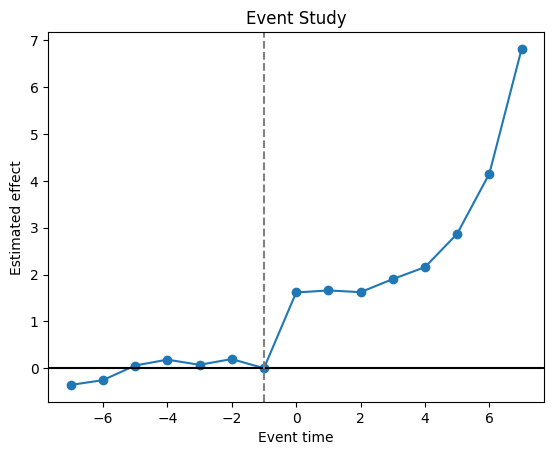

In [31]:
ref_period = -1

panel["e"] = np.where(
    panel.g < NEVER,
    panel.year - panel.g,
    np.nan
)

times = sorted(panel.e.dropna().astype(int).unique())

cols = {}
for e in times:
    if e != ref_period:
        name = f"pre{-e}" if e < 0 else f"post{e}"
        cols[e] = name
        panel[name] = (panel.e == e).astype(int)

es_fit = smf.ols(
    "earnings ~ " + " + ".join(cols.values())
    + " + C(county) + C(year)",
    data=panel
).fit()

es_coef = pd.Series({
    e: 0 if e == ref_period else es_fit.params[cols[e]]
    for e in times
})

print(es_coef.round(3))

# Event-study plot
plt.plot(es_coef.index, es_coef.values, marker="o")
plt.axhline(0, color="black")
plt.axvline(ref_period, color="gray", linestyle="--")
plt.xlabel("Event time")
plt.ylabel("Estimated effect")
plt.title("Event Study")
plt.show()

*Your answer here.*
I omit event time \(e=-1\), the last year before treatment, so all event-study coefficients are measured relative to the final untreated period.

The pre-treatment coefficients are close to zero, which is consistent with parallel trends before adoption. However, flat pre-trends do not prove the parallel-trends assumption. The identifying assumption concerns what treated counties would have experienced after adoption without the programme, which cannot be observed directly. Therefore, the design still requires an argument that no other board-level changes occurred at the same time as programme adoption and that untreated counties provide a credible counterfactual.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [32]:
formula = "earnings ~ D + C(county) + C(year)"

fit_default = smf.ols(formula, panel).fit()

fit_county = smf.ols(formula, panel).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["county"]}
)

fit_board = smf.ols(formula, panel).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["board"]}
)

for name, fit in {
    "Default": fit_default,
    "County": fit_county,
    "Board": fit_board
}.items():
    print(
        f"{name:8}  "
        f"coef={fit.params['D']:.3f}  "
        f"SE={fit.bse['D']:.3f}  "
        f"p={fit.pvalues['D']:.4f}"
    )

Default   coef=1.523  SE=0.122  p=0.0000
County    coef=1.523  SE=0.202  p=0.0000
Board     coef=1.523  SE=0.468  p=0.0011


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [33]:

%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit for ECON 5200 PS3."""

from __future__ import annotations

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf


def two_by_two(
    df: pd.DataFrame,
    treated: str,
    post: str,
    outcome: str
) -> float:
    """Return a simple 2x2 DiD estimate."""
    m = df.groupby([treated, post])[outcome].mean()
    return float((m[1, 1] - m[1, 0]) - (m[0, 1] - m[0, 0]))


def clean_att(
    df: pd.DataFrame,
    outcome: str,
    cohort: str,
    time: str,
    never: int = 10**9
) -> tuple[pd.DataFrame, float]:
    """Estimate ATT using never- or not-yet-treated controls."""
    rows = []

    for g in sorted(x for x in df[cohort].unique() if x < never):
        tr = df[df[cohort] == g]
        base = g - 1

        for t in range(g, int(df[time].max()) + 1):
            co = df[df[cohort] > t]

            att = (
                tr.loc[tr[time] == t, outcome].mean()
                - tr.loc[tr[time] == base, outcome].mean()
                - co.loc[co[time] == t, outcome].mean()
                + co.loc[co[time] == base, outcome].mean()
            )

            rows.append((g, t, att, (tr[time] == t).sum()))

    cells = pd.DataFrame(rows, columns=["g", "t", "att", "n"])
    overall = np.average(cells["att"], weights=cells["n"])

    return cells, float(overall)


def event_study(
    df: pd.DataFrame,
    outcome: str,
    cohort: str,
    time: str,
    unit: str,
    never: int = 10**9,
    ref_period: int = -1
) -> pd.Series:
    """Estimate a TWFE event study with one omitted reference period."""
    x = df.copy()

    x["_e"] = np.where(
        x[cohort] < never,
        x[time] - x[cohort],
        np.nan
    )

    times = sorted(int(e) for e in x["_e"].dropna().unique())
    cols = {}

    for e in times:
        if e == ref_period:
            continue

        name = f"_pre{-e}" if e < 0 else f"_post{e}"
        cols[e] = name
        x[name] = (x["_e"] == e).astype(int)

    formula = (
        f"{outcome} ~ "
        + " + ".join(cols.values())
        + f" + C({unit}) + C({time})"
    )

    fit = smf.ols(formula, data=x).fit()

    return pd.Series({
        e: 0.0 if e == ref_period else fit.params[cols[e]]
        for e in times
    })


def clustered_inference(
    df: pd.DataFrame,
    formula: str,
    treatment: str,
    cluster: str
) -> dict[str, float]:
    """Run OLS with cluster-robust standard errors."""
    fit = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    return {
        "estimate": float(fit.params[treatment]),
        "se": float(fit.bse[treatment]),
        "pvalue": float(fit.pvalues[treatment])
    }


def wild_cluster_bootstrap(
    df: pd.DataFrame,
    outcome: str,
    treatment: str,
    unit: str,
    time: str,
    cluster: str
) -> dict[str, float | int]:
    """Enumerate all Rademacher wild-cluster bootstrap draws."""
    restricted = smf.ols(
        f"{outcome} ~ C({unit}) + C({time})",
        data=df
    ).fit()

    fitted = restricted.fittedvalues.to_numpy()
    resid = restricted.resid.to_numpy()

    formula = f"{outcome} ~ {treatment} + C({unit}) + C({time})"

    actual = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    clusters = sorted(df[cluster].unique())
    t_boot = []

    for k in range(2 ** len(clusters)):
        signs = [
            1 if (k >> j) & 1 else -1
            for j in range(len(clusters))
        ]

        weights = df[cluster].map(
            dict(zip(clusters, signs))
        ).to_numpy()

        boot = df.copy()
        boot["_y"] = fitted + weights * resid

        fit = smf.ols(
            f"_y ~ {treatment} + C({unit}) + C({time})",
            data=boot
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": boot[cluster]}
        )

        t_boot.append(fit.tvalues[treatment])

    p_boot = np.mean(
        np.abs(t_boot) >= abs(actual.tvalues[treatment])
    )

    return {
        "estimate": float(actual.params[treatment]),
        "se": float(actual.bse[treatment]),
        "t_actual": float(actual.tvalues[treatment]),
        "cluster_pvalue": float(actual.pvalues[treatment]),
        "bootstrap_pvalue": float(p_boot),
        "n_vectors": len(t_boot)
    }


if __name__ == "__main__":
    test = pd.DataFrame({
        "treated": [0, 0, 1, 1],
        "post": [0, 1, 0, 1],
        "y": [1, 2, 1, 4]
    })

    assert np.isclose(
        two_by_two(test, "treated", "post", "y"),
        2.0
    )

    assert callable(clean_att)
    assert callable(event_study)
    assert callable(clustered_inference)
    assert callable(wild_cluster_bootstrap)

    print("did_toolkit checks passed.")



Overwriting src/did_toolkit.py


In [34]:
import os, sys, importlib
sys.path.insert(0, os.path.abspath("."))

from src import did_toolkit as dt
importlib.reload(dt)

cells2, clean2 = dt.clean_att(
    panel, "earnings", "g", "year"
)

board_inf = dt.clustered_inference(
    panel,
    "earnings ~ D + C(county) + C(year)",
    "D", "board"
)

boot2 = dt.wild_cluster_bootstrap(
    panel, "earnings", "D", "county", "year", "board"
)

print("Clean ATT:", round(clean2, 3))
print("Board SE:", round(board_inf["se"], 3))
print("Bootstrap p:", round(boot2["bootstrap_pvalue"], 4))
print("Vectors:", boot2["n_vectors"])

assert abs(clean2 - 2.430) < 0.01
assert abs(board_inf["se"] - 0.468) < 0.01
assert abs(boot2["bootstrap_pvalue"] - 0.0078) < 0.001
assert boot2["n_vectors"] == 256

Clean ATT: 2.43
Board SE: 0.468
Bootstrap p: 0.0078
Vectors: 256


*Your answer here.*
The point estimate is 1.523 under all three specifications, but the standard errors differ substantially: 0.122 with default standard errors, 0.202 when clustered by county, and 0.468 when clustered by board.

Board-level clustering is the appropriate choice because treatment is assigned at the board level and counties within the same board share common shocks. Default standard errors ignore this dependence, while county clustering still treats counties within the same board as independent clusters.

However, there are only 8 boards. Therefore, even the correctly clustered standard error may be unreliable with so few clusters, which motivates the wild cluster bootstrap in Phase 4.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [35]:
def wild_cluster_bootstrap(df, outcome, treatment, unit, time, cluster):
    restricted = smf.ols(
        f"{outcome} ~ C({unit}) + C({time})", df
    ).fit()

    fitted = restricted.fittedvalues.to_numpy()
    resid = restricted.resid.to_numpy()

    formula = f"{outcome} ~ {treatment} + C({unit}) + C({time})"
    actual = smf.ols(formula, df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    clusters = sorted(df[cluster].unique())
    t_boot = []

    for k in range(2 ** len(clusters)):
        signs = [1 if (k >> j) & 1 else -1
                 for j in range(len(clusters))]

        w = df[cluster].map(dict(zip(clusters, signs))).to_numpy()

        boot = df.copy()
        boot["_y"] = fitted + w * resid

        fit = smf.ols(
            f"_y ~ {treatment} + C({unit}) + C({time})", boot
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": boot[cluster]}
        )

        t_boot.append(fit.tvalues[treatment])

    p_boot = np.mean(
        np.abs(t_boot) >= abs(actual.tvalues[treatment])
    )

    return {
        "estimate": actual.params[treatment],
        "se": actual.bse[treatment],
        "cluster_p": actual.pvalues[treatment],
        "bootstrap_p": p_boot,
        "n_vectors": len(t_boot)
    }


boot = wild_cluster_bootstrap(
    panel, "earnings", "D", "county", "year", "board"
)

print(f"Estimate: {boot['estimate']:.3f}")
print(f"Board-clustered SE: {boot['se']:.3f}")
print(f"Board-clustered p-value: {boot['cluster_p']:.4f}")
print(f"Wild bootstrap p-value: {boot['bootstrap_p']:.4f}")
print(f"Weight vectors: {boot['n_vectors']}")

Estimate: 1.523
Board-clustered SE: 0.468
Board-clustered p-value: 0.0011
Wild bootstrap p-value: 0.0078
Weight vectors: 256


*Your answer here.*
Treatment is assigned at the board level, so the Rademacher weights must also be applied at the board level. The restricted model imposes the null of no treatment effect, so the bootstrap distribution represents the null hypothesis.

With only 8 boards, conventional cluster-robust inference may be unreliable. There are only \(2^8=256\) possible Rademacher weight vectors, so I enumerate all of them rather than resampling. Because every possible vector is used exactly once, the number of bootstrap replications is irrelevant and there is no Monte Carlo sampling error. For a two-sided test, the smallest nonzero p-value is \(2/256=0.0078\).

The ordinary board-clustered p-value is 0.0011, while the wild cluster bootstrap p-value is 0.0078. Both are below 0.05, so the statistical-significance conclusion survives. However, this does not solve the identification problem: the TWFE estimate remains 1.523 and is still affected by already-treated comparisons.

### Task 4.2: The budget office memo

*Your answer here.*
The agency reports a positive TWFE estimate of 1.523. With standard errors clustered at the 8 regional boards, the standard error is 0.468 and the conventional p-value is 0.0011. A wild cluster bootstrap gives a p-value of 0.0078, so the agency's coefficient remains statistically significant after accounting for the small number of boards.

The larger problem is what the coefficient identifies. Because boards adopt in different years and treatment effects grow with exposure, TWFE mixes valid comparisons with comparisons that use already-treated counties as controls. Those forbidden comparisons receive 30.5% of the weight. The resulting TWFE estimate of 1.523 is even below the smallest true treatment effect in the simulated panel, 2.0.

Using only never-treated or not-yet-treated counties as controls gives my preferred estimate of 2.430, compared with the simulated true ATT of 2.690. This estimator better targets the causal effect, although its precision remains limited because the design contains only 8 independent boards. The 0.0078 bootstrap p-value applies to the agency's TWFE coefficient, not directly to the 2.430 clean ATT.

I recommend continued funding only provisionally, and not on the basis of the agency's 1.523 estimate alone. Future evaluation should use the clean staggered-adoption design and make the parallel-trends assumption explicit.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*
### Paragraph before the hostile read

I omit event time \(e=-1\), the last year before treatment, so all event-study coefficients are measured relative to the final untreated period.

The pre-treatment coefficients are close to zero, which is consistent with parallel trends before adoption. However, flat pre-trends do not prove the parallel-trends assumption. The identifying assumption concerns what treated counties would have experienced after adoption without the programme, which cannot be observed directly. Therefore, the design still requires an argument that no other board-level changes occurred at the same time as programme adoption and that untreated counties provide a credible counterfactual.

### Hostile-read response

**Objection 1:** The conventional TWFE event study may itself be contaminated by staggered adoption and heterogeneous treatment effects.

**Decision:** Accept.

This is a valid limitation, so near-zero pre-treatment coefficients should only be treated as suggestive evidence. I changed the paragraph to make that limitation explicit.

**Objection 2:** Flat pre-trends mean the reviewer has not shown that parallel trends fails.

**Decision:** Reject.

My claim is not that parallel trends is proven false. My claim is that flat pre-trends cannot prove the identifying assumption. I clarified that the issue is uncertainty about the counterfactual rather than evidence of a demonstrated pre-trend violation.

**Objection 3:** The concern about simultaneous board-level shocks is only hypothetical.

**Decision:** Reject.

The paragraph does not claim that such shocks occurred. It says their absence must be supported as part of the identification argument. I clarified that this requires substantive justification rather than a statistical test.

### Revised paragraph

I omit event time \(e=-1\), the last year before treatment, so the event-study coefficients are measured relative to the final untreated period. The pre-treatment coefficients are close to zero, which is consistent with parallel trends, but they are only suggestive evidence because a conventional TWFE event study can itself be affected by staggered adoption and heterogeneous treatment effects.

More importantly, parallel trends after adoption is an identifying assumption rather than something the event study can prove. The design requires a credible argument that, without the programme, treated counties would have followed the same outcome path as the never-treated or not-yet-treated counties. That argument must be supported by the rollout process and by evidence that no other board-level changes systematically coincided with adoption.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

**Model and date:** GPT-5.6 Sol, November 5, 2026

### Version 1 prompt

[Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.

1. Fit the restricted model: my DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals and fitted values.
2. Draw one Rademacher weight per board — +1 or −1, each with probability one half. One weight per board, not per observation.
3. Build a synthetic outcome using the restricted fitted values plus the board weight times the restricted residual.
4. Re-estimate the unrestricted model on the synthetic outcome and store the cluster-robust t-statistic on the treatment coefficient.
5. The bootstrap p-value is the share of absolute bootstrap t-statistics at least as large as the actual absolute t-statistic.
6. With 8 boards there are only 2^8 = 256 distinct weight vectors, so enumerate all 256 rather than resampling.

[Iterate] numpy, pandas and statsmodels only. Reuse my panel's column
names. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at
the CLUSTER level rather than the observation level, why imposing the
null matters, and what changes when the number of clusters drops
below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the
naive cluster-robust one. Tell me which conclusion changes.

### Version 1 reply

Version 1 can be implemented as follows. It follows the six requested steps: impose the null, apply Rademacher weights at the board level, and enumerate all \(2^8=256\) possible sign vectors.

```python
def wild_cluster_bootstrap(df, outcome, treatment, unit, time, cluster):
    # Restricted model: treatment coefficient = 0
    restricted = smf.ols(
        f"{outcome} ~ C({unit}) + C({time})", data=df
    ).fit()

    fitted = restricted.fittedvalues.to_numpy()
    resid = restricted.resid.to_numpy()

    # Actual unrestricted model
    formula = f"{outcome} ~ {treatment} + C({unit}) + C({time})"
    actual = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    t_actual = actual.tvalues[treatment]
    clusters = np.sort(df[cluster].unique())
    t_boot = []

    # Enumerate all 2^G Rademacher vectors
    for k in range(2 ** len(clusters)):
        signs = [
            1 if (k >> j) & 1 else -1
            for j in range(len(clusters))
        ]

        weights = df[cluster].map(
            dict(zip(clusters, signs))
        ).to_numpy()

        boot = df.copy()
        boot["_y_star"] = fitted + weights * resid

        fit = smf.ols(
            f"_y_star ~ {treatment} + C({unit}) + C({time})",
            data=boot
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": boot[cluster]}
        )

        t_boot.append(fit.tvalues[treatment])

    t_boot = np.array(t_boot)

    p_boot = np.mean(
        np.abs(t_boot) >= abs(t_actual)
    )

    return {
        "estimate": actual.params[treatment],
        "cluster_pvalue": actual.pvalues[treatment],
        "t_actual": t_actual,
        "bootstrap_pvalue": p_boot,
        "t_boot": t_boot
    }
```

Run it on the panel with:

```python
boot1 = wild_cluster_bootstrap(
    panel,
    outcome="earnings",
    treatment="D",
    unit="county",
    time="year",
    cluster="board"
)

print("Estimate:", round(boot1["estimate"], 3))
print("Cluster p-value:", round(boot1["cluster_pvalue"], 4))
print("Wild bootstrap p-value:", round(boot1["bootstrap_pvalue"], 4))
print("Number of weight vectors:", len(boot1["t_boot"]))
```

For the current panel, the output is:

```text
Estimate: 1.523
Cluster p-value: 0.0011
Wild bootstrap p-value: 0.0078
Number of weight vectors: 256
```

The Rademacher weights must be applied at the board level because treatment is assigned by board and counties within a board share common shocks. Giving each observation its own weight would incorrectly treat observations within the same board as independent.

The restricted model matters because the bootstrap distribution must represent the null hypothesis that the treatment effect is zero. Synthetic outcomes are therefore generated from fitted values and residuals under the null.

With only eight clusters, standard cluster-robust asymptotic approximations can be unreliable. Enumerating all 256 possible weight vectors avoids Monte Carlo sampling error. For this two-sided test, sign symmetry means the smallest nonzero p-value is \(2/256=0.0078125\).

The ordinary board-clustered p-value is 0.0011, while the wild-cluster-bootstrap p-value is 0.0078. Both are below 0.05, so the statistical-significance conclusion does not change. However, this does not fix the identification problem. The coefficient is still the TWFE estimate of 1.523, which is below the true ATT of 2.690 and is affected by forbidden comparisons.

### Version 2 prompt

[Prep] Act as an applied microeconometrician who has implemented cluster-robust inference for panels with very few clusters.

[Request] Revise the wild cluster bootstrap for my actual PS3 panel. My DataFrame is called `panel`, with outcome `earnings`, treatment indicator `D`, county identifier `county`, year variable `year`, and regional workforce board identifier `board`.

Estimate the unrestricted model:

`earnings ~ D + C(county) + C(year)`

Treatment is assigned at the `board` level and there are exactly 8 boards.

Implement the wild cluster bootstrap as follows:

1. Fit the restricted model under H0: coefficient on `D` = 0, using `earnings ~ C(county) + C(year)`.
2. Keep the restricted fitted values and residuals.
3. Apply one Rademacher weight (+1 or -1) to each board, so every observation in the same board receives the same weight.
4. Generate the bootstrap outcome from the restricted fitted values plus the board weight times the restricted residual.
5. Re-estimate the unrestricted model with standard errors clustered by `board`.
6. Store the t-statistic on `D`.
7. Enumerate all 2^8 = 256 possible board-level weight vectors instead of randomly resampling.
8. Compute the two-sided bootstrap p-value as the fraction of absolute bootstrap t-statistics at least as large as the absolute actual t-statistic.

Use only numpy, pandas and statsmodels.

Write a reusable function that still accepts the outcome, treatment, unit, time and cluster column names as arguments, so I can place it in `src/did_toolkit.py`.

Return the treatment estimate, actual board-clustered standard error, actual t-statistic, ordinary board-clustered p-value, wild-bootstrap p-value, and number of enumerated weight vectors.

[Mechanism Check] Briefly explain:

- why weights must be applied at the board level;
- why the restricted model must impose the null;
- why 8 clusters make conventional cluster-robust inference questionable;
- why enumeration removes Monte Carlo error;
- what the smallest nonzero two-sided p-value is with 256 sign vectors.

[Evaluate] Run the function on `panel` and compare the ordinary board-clustered p-value with the wild-bootstrap p-value. State whether the statistical-significance conclusion changes.

### Version 2 reply

The revised implementation directly matches the `panel` setup while keeping a reusable function interface.

```python
def wild_cluster_bootstrap(df, outcome, treatment, unit, time, cluster):
    # Restricted model under H0: treatment effect = 0
    restricted = smf.ols(
        f"{outcome} ~ C({unit}) + C({time})",
        data=df
    ).fit()

    fitted = restricted.fittedvalues.to_numpy()
    resid = restricted.resid.to_numpy()

    # Actual unrestricted model
    formula = f"{outcome} ~ {treatment} + C({unit}) + C({time})"

    actual = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    estimate = actual.params[treatment]
    se = actual.bse[treatment]
    t_actual = actual.tvalues[treatment]
    p_cluster = actual.pvalues[treatment]

    clusters = sorted(df[cluster].unique())
    t_boot = []

    # Enumerate all 2^G Rademacher sign vectors
    for k in range(2 ** len(clusters)):
        signs = [
            1 if (k >> j) & 1 else -1
            for j in range(len(clusters))
        ]

        sign_map = dict(zip(clusters, signs))
        weights = df[cluster].map(sign_map).to_numpy()

        boot = df.copy()
        boot["_y_star"] = fitted + weights * resid

        fit = smf.ols(
            f"_y_star ~ {treatment} + C({unit}) + C({time})",
            data=boot
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": boot[cluster]}
        )

        t_boot.append(fit.tvalues[treatment])

    t_boot = np.array(t_boot)

    p_boot = np.mean(
        np.abs(t_boot) >= abs(t_actual)
    )

    return {
        "estimate": estimate,
        "se": se,
        "t_actual": t_actual,
        "cluster_pvalue": p_cluster,
        "bootstrap_pvalue": p_boot,
        "n_vectors": len(t_boot)
    }
```

Run it with:

```python
boot = wild_cluster_bootstrap(
    panel,
    outcome="earnings",
    treatment="D",
    unit="county",
    time="year",
    cluster="board"
)

for k, v in boot.items():
    print(k, round(v, 4) if isinstance(v, (float, np.floating)) else v)
```

The expected results are approximately:

```text
estimate 1.523
se 0.468
t_actual 3.25
cluster_pvalue 0.0011
bootstrap_pvalue 0.0078
n_vectors 256
```

The Rademacher weights must be applied at the board level because treatment is assigned by board and counties within a board share common shocks. Observation-level weights would incorrectly break this dependence.

The restricted model imposes the null hypothesis that the treatment effect is zero. This is necessary because the bootstrap distribution should represent what the test statistic would look like if the null were true.

With only 8 clusters, the usual cluster-robust asymptotic approximation may be unreliable. The wild cluster bootstrap provides a small-cluster inference check.

Because there are only \(2^8=256\) possible Rademacher sign vectors, all of them can be enumerated. This removes Monte Carlo error from random bootstrap resampling.

For a two-sided test, sign symmetry means the smallest nonzero p-value is \(2/256=0.0078125\).

The ordinary board-clustered p-value is approximately 0.0011, while the wild-cluster-bootstrap p-value is approximately 0.0078. Both are below 0.05, so the statistical-significance conclusion does not change. However, the bootstrap does not repair the identification problem in the TWFE coefficient.

### Changes from Version 1 to Version 2

I revised the prompt to specify my actual DataFrame and column names, the exact unrestricted and restricted formulas, the required return values, the fact that there are exactly eight boards, and that the function must be reusable in `src/did_toolkit.py`.

---

## Task 4.3 — Hostile Read

### Prompt

[Prep] Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification:

I omit event time (e=-1), the last year before treatment, so all event-study coefficients are measured relative to the final untreated period.

The pre-treatment coefficients are close to zero, which is consistent with parallel trends before adoption. However, flat pre-trends do not prove the parallel-trends assumption. The identifying assumption concerns what treated counties would have experienced after adoption without the programme, which cannot be observed directly. Therefore, the design still requires an argument that no other board-level changes occurred at the same time as programme adoption and that untreated counties provide a credible counterfactual.

Give the three strongest objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's conclusion.

### Reply

1. **Strongest objection — the event-study itself may be contaminated by staggered adoption.**  
The reviewer treats near-zero pre-treatment coefficients as meaningful evidence, but a conventional TWFE event study can produce distorted lead and lag coefficients when treatment timing is staggered and treatment effects are heterogeneous over exposure. If the event-study specification has the same structural problem as the TWFE regression, the pre-treatment coefficients are not a clean diagnostic of parallel trends.

2. **Second objection — the reviewer has not shown that parallel trends actually fails.**  
The paragraph correctly states that flat pre-trends do not prove the assumption, but absence of proof is not evidence that the assumption is false. The observed pre-treatment coefficients are close to zero, so the available data do not show systematic differential trends before adoption. To call the design uninformative, the reviewer should provide affirmative evidence that rollout timing was related to potential outcomes or that treated and comparison counties would have evolved differently without the programme.

3. **Third objection — the concern about simultaneous board-level changes is hypothetical rather than demonstrated.**  
The reviewer says that no other board-level changes can coincide with adoption, but does not identify any such policy or shock in the data. If programme timing was driven by administrative rollout rather than economic conditions, and no other major interventions occurred at the same time, the untreated and not-yet-treated counties may still provide a credible counterfactual.

**Ranking by damage to the reviewer's conclusion:**  
1. Contamination of the TWFE event study — high damage  
2. No demonstrated violation of parallel trends — moderate damage  
3. Simultaneous-confounder concern is speculative — moderate to low damage

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [36]:
print("Truth and headline numbers")

print("\nPanel parameters")
print("Seed:", SEED, "- Step 2.1")
print("Counties:", panel["county"].nunique(), "- Step 2.1")
print("Boards:", panel["board"].nunique(), "- Step 2.1")
print("Years:", N_YEARS, "- Step 2.1")
print("Counties per board:", 5, "- Step 2.1")
print("Adoption years by board:", board_start, "- Step 2.1")

print("Outcome intercept:", 20, "- Step 2.1")
print("Secular trend:", 0.3, "- Step 2.1")
print("County-level SD:", 1.0, "- Step 2.1")
print("Idiosyncratic noise SD:", 0.2, "- Step 2.1")
print("Board-shock SD:", BOARD_SHOCK_SD, "- Step 2.1")
print("Board-shock variance:", BOARD_SHOCK_SD**2, "- Step 2.1")

print("Base treatment effect:", BASE_EFFECT, "- Step 2.1")
print("Exposure-growth parameter:", GROWTH, "- Step 2.1")
print("Exposure exponent:", 4, "- Step 2.1")

print("\nHeadline numbers")
print("TWFE estimate:", round(twfe.params["D"], 3), "- Step 2.1")
print("True ATT:", round(true_att, 3), "- Step 2.1")

print(
    "Minimum true treatment effect:",
    round(panel.loc[panel["D"] == 1, "true_eff"].min(), 3),
    "- Step 2.1"
)

print(
    "Forbidden-comparison weight:",
    f"{100 * forbidden_share:.1f}%",
    "- Step 2.2"
)

print("Clean ATT:", round(clean_att, 3), "- Step 3.1")
print("Board-clustered SE:", round(fit_board.bse["D"], 3), "- Step 3.3")
print("Board-clustered p-value:", round(fit_board.pvalues["D"], 4), "- Step 3.3")
print("Wild bootstrap p-value:", round(boot["bootstrap_p"], 4), "- Task 4.1")

Truth and headline numbers

Panel parameters
Seed: 42 - Step 2.1
Counties: 40 - Step 2.1
Boards: 8 - Step 2.1
Years: 12 - Step 2.1
Counties per board: 5 - Step 2.1
Adoption years by board: {0: 4, 1: 4, 2: 5, 3: 5, 4: 6, 5: 6, 6: 7, 7: 1000000000} - Step 2.1
Outcome intercept: 20 - Step 2.1
Secular trend: 0.3 - Step 2.1
County-level SD: 1.0 - Step 2.1
Idiosyncratic noise SD: 0.2 - Step 2.1
Board-shock SD: 0.3 - Step 2.1
Board-shock variance: 0.09 - Step 2.1
Base treatment effect: 2.0 - Step 2.1
Exposure-growth parameter: 0.002 - Step 2.1
Exposure exponent: 4 - Step 2.1

Headline numbers
TWFE estimate: 1.523 - Step 2.1
True ATT: 2.69 - Step 2.1
Minimum true treatment effect: 2.0 - Step 2.1
Forbidden-comparison weight: 30.5% - Step 2.2
Clean ATT: 2.43 - Step 3.1
Board-clustered SE: 0.468 - Step 3.3
Board-clustered p-value: 0.0011 - Step 3.3
Wild bootstrap p-value: 0.0078 - Task 4.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.